In [3]:
%load_ext autoreload
%autoreload 2

In [4]:
import sys
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
import numpy as np
from tqdm import tqdm

from pathlib import Path
sys.path.append(str(Path.cwd().parents[0] / "src"))
from plotting import *
from HeteroBilayer import HeteroBilayer
import utils
import analytic_metric

### Create Moiré system

In [97]:
sys = HeteroBilayer(theta_deg=2.0, V=4, psi_deg=0)

### Band structure

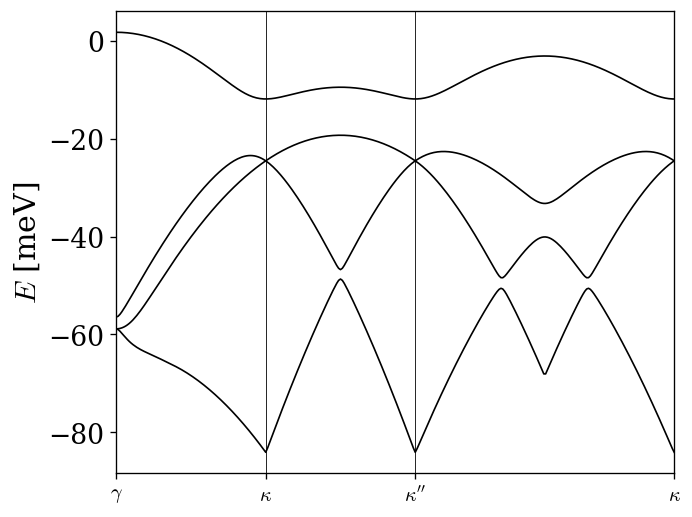

In [98]:
kpath, kdist, ticks = sys.make_k_path(*sys.default_path, n_pts=300)
bands, _ = sys.calculate_bands(kpath=kpath)

fig, ax = plt.subplots()
plot_bands(ax, bands, kdist, ticks, max_bands=4)
# plt.ylim([-60, 10])
plt.savefig("plots/two_bands.svg", dpi=300, bbox_inches="tight", transparent=True, pad_inches=0)

In [99]:
sys.calculate_bandwidth()

13.616296323611842

### Moiré potential

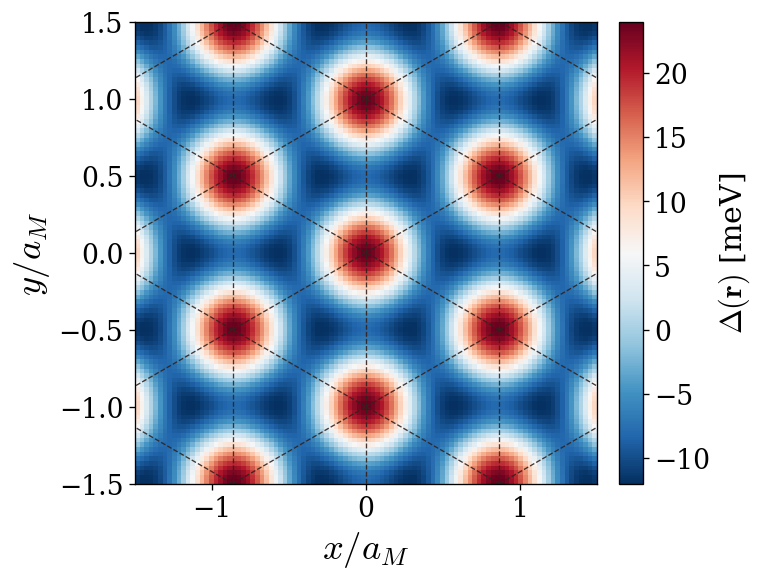

In [100]:
fig, ax = plt.subplots()
scale = 1.5
extent = [-scale, scale, -scale, scale]
im = plot_moire_potential(sys, ax, extent, resolution=100)
plot_triangular_lattice(sys, ax, extent)

ax.set_xlabel(r'$x/a_M$', fontsize=22)
ax.set_ylabel(r'$y/a_M$', fontsize=22)
plt.savefig("plots/moire_potential.svg", dpi=300, bbox_inches='tight', transparent=True, pad_inches=0)

### Wannier function

Norm Wannier:  0.9942442912036913


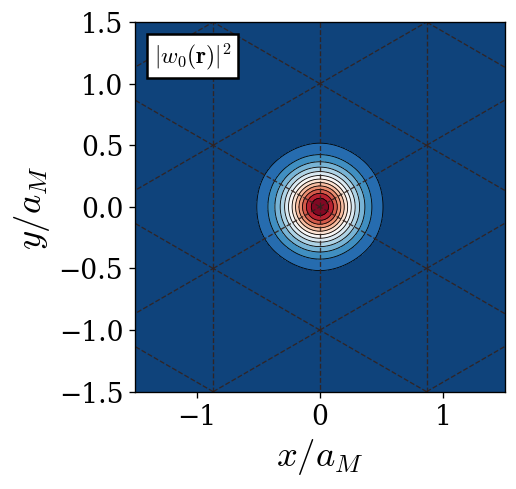

In [8]:
fig, ax = plt.subplots(1, 1, figsize=(5, 4))
scale = 1.5
x = np.linspace(-scale, scale, 300)
y = np.linspace(-scale, scale, 300)
X, Y = np.meshgrid(x, y)

wannier = sys.wannier_function(X, Y, trial_centers=[np.zeros(2)], R0=np.zeros(2))
norm = sys.integrate_wannier(lambda x, y: 1.0, wannier, X, Y)
print("Norm Wannier: ", norm)

plot_wannier_function(sys, ax, X, Y, cmap='RdBu_r')

plt.savefig("plots/wannier_function.svg", dpi=300, bbox_inches='tight', transparent=True)

Norm Wannier A:  0.9871781628530235
Norm Wannier B:  0.9764113326971178


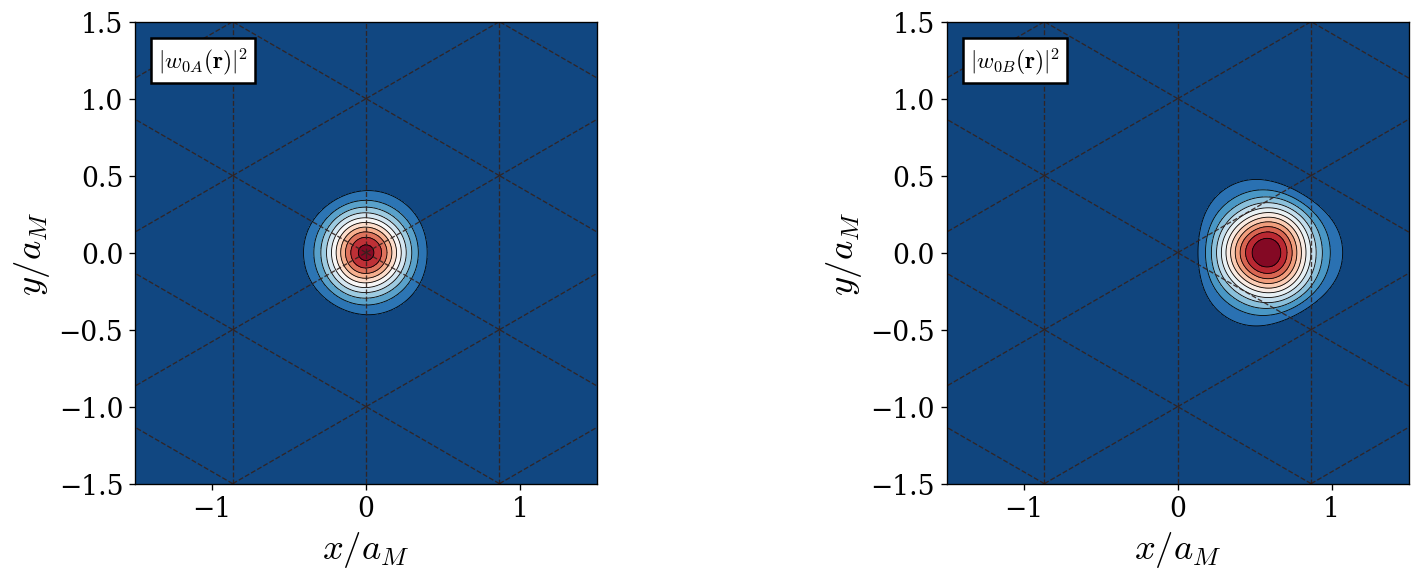

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(16, 5))
scale = 1.5
x = np.linspace(-scale, scale, 300)
y = np.linspace(-scale, scale, 300)
X, Y = np.meshgrid(x, y)

## Trial functions centers
RA = np.zeros(2)
RB = (2 * sys.a1 - sys.a2) / 3
##

wanniers = sys.wannier_function(X, Y, trial_centers=np.array([RA, RB]), bands=(-2, -1))
wannierA = wanniers[0, :, :]
wannierB = wanniers[1, :, :]
normA = sys.integrate_wannier(lambda x, y: 1.0, wannierA, X, Y)
normB = sys.integrate_wannier(lambda x, y: 1.0, wannierB, X, Y)
print("Norm Wannier A: ", normA)
print("Norm Wannier B: ", normB)

plot_wannier_function(sys, ax, X, Y, trial_centers=np.array([RA, RB]), bands=(-2, -1), cmap='RdBu_r')

In [66]:
R_MM = np.array([0.0, 0.0])

W = sys.wannier_function_v2(
    X, Y,
    trial_centers=[R_MM, R_MM],
    trial_types=["s", "s"],
    bands=(-2, -1),
    sigma=0.5,
)

RuntimeError: Projection is ill-conditioned at k=0: smallest singular value = 0.000e+00

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# s-like Wannier function
im0 = axes[0].pcolormesh(
    X, Y,
    np.real(W[0]),
    shading="auto",
    cmap="RdBu_r"
)
axes[0].set_title(r"$W_s$")
axes[0].set_aspect("equal")
axes[0].set_xlabel("$x$")
axes[0].set_ylabel("$y$")
axes[0].scatter(
    x_MM, y_MM,
    color="black",
    marker="x",
    s=80,
    label="MM"
)
axes[0].legend()
fig.colorbar(im0, ax=axes[0], label=r"$\mathrm{Re}\,W_s$")


# px-like Wannier function
im1 = axes[1].pcolormesh(
    X, Y,
    np.real(W[1]),
    shading="auto",
    cmap="RdBu_r"
)
axes[1].set_title(r"$W_{p_x}$")
axes[1].set_aspect("equal")
axes[1].set_xlabel("$x$")
axes[1].set_ylabel("$y$")
axes[1].scatter(
    x_MM, y_MM,
    color="black",
    marker="x",
    s=80,
    label="MM"
)
axes[1].legend()
fig.colorbar(im1, ax=axes[1], label=r"$\mathrm{Re}\,W_{p_x}$")

plt.tight_layout()
plt.show()

### Berry curvature

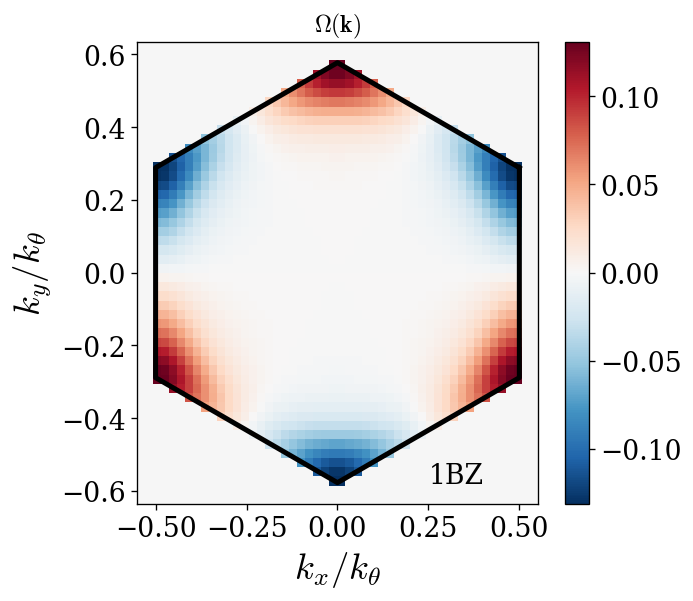

In [35]:
fig, ax = plt.subplots()
scale = 1.1
kx = np.linspace(-scale * sys.kappa_pp[0], scale * sys.kappa_pp[0], 50)
ky = np.linspace(-scale * sys.kappa_p[1], scale * sys.kappa_p[1], 50)
KX, KY = np.meshgrid(kx, ky)
plot_berry_curvature(sys, ax, KX, KY)

plt.xlabel(r'$k_x / k_\theta$', fontsize=22)
plt.ylabel(r'$k_y / k_\theta$', fontsize=22)
plt.savefig("plots/berry_curvature.pdf", dpi=300, bbox_inches='tight')

### Quantum metric

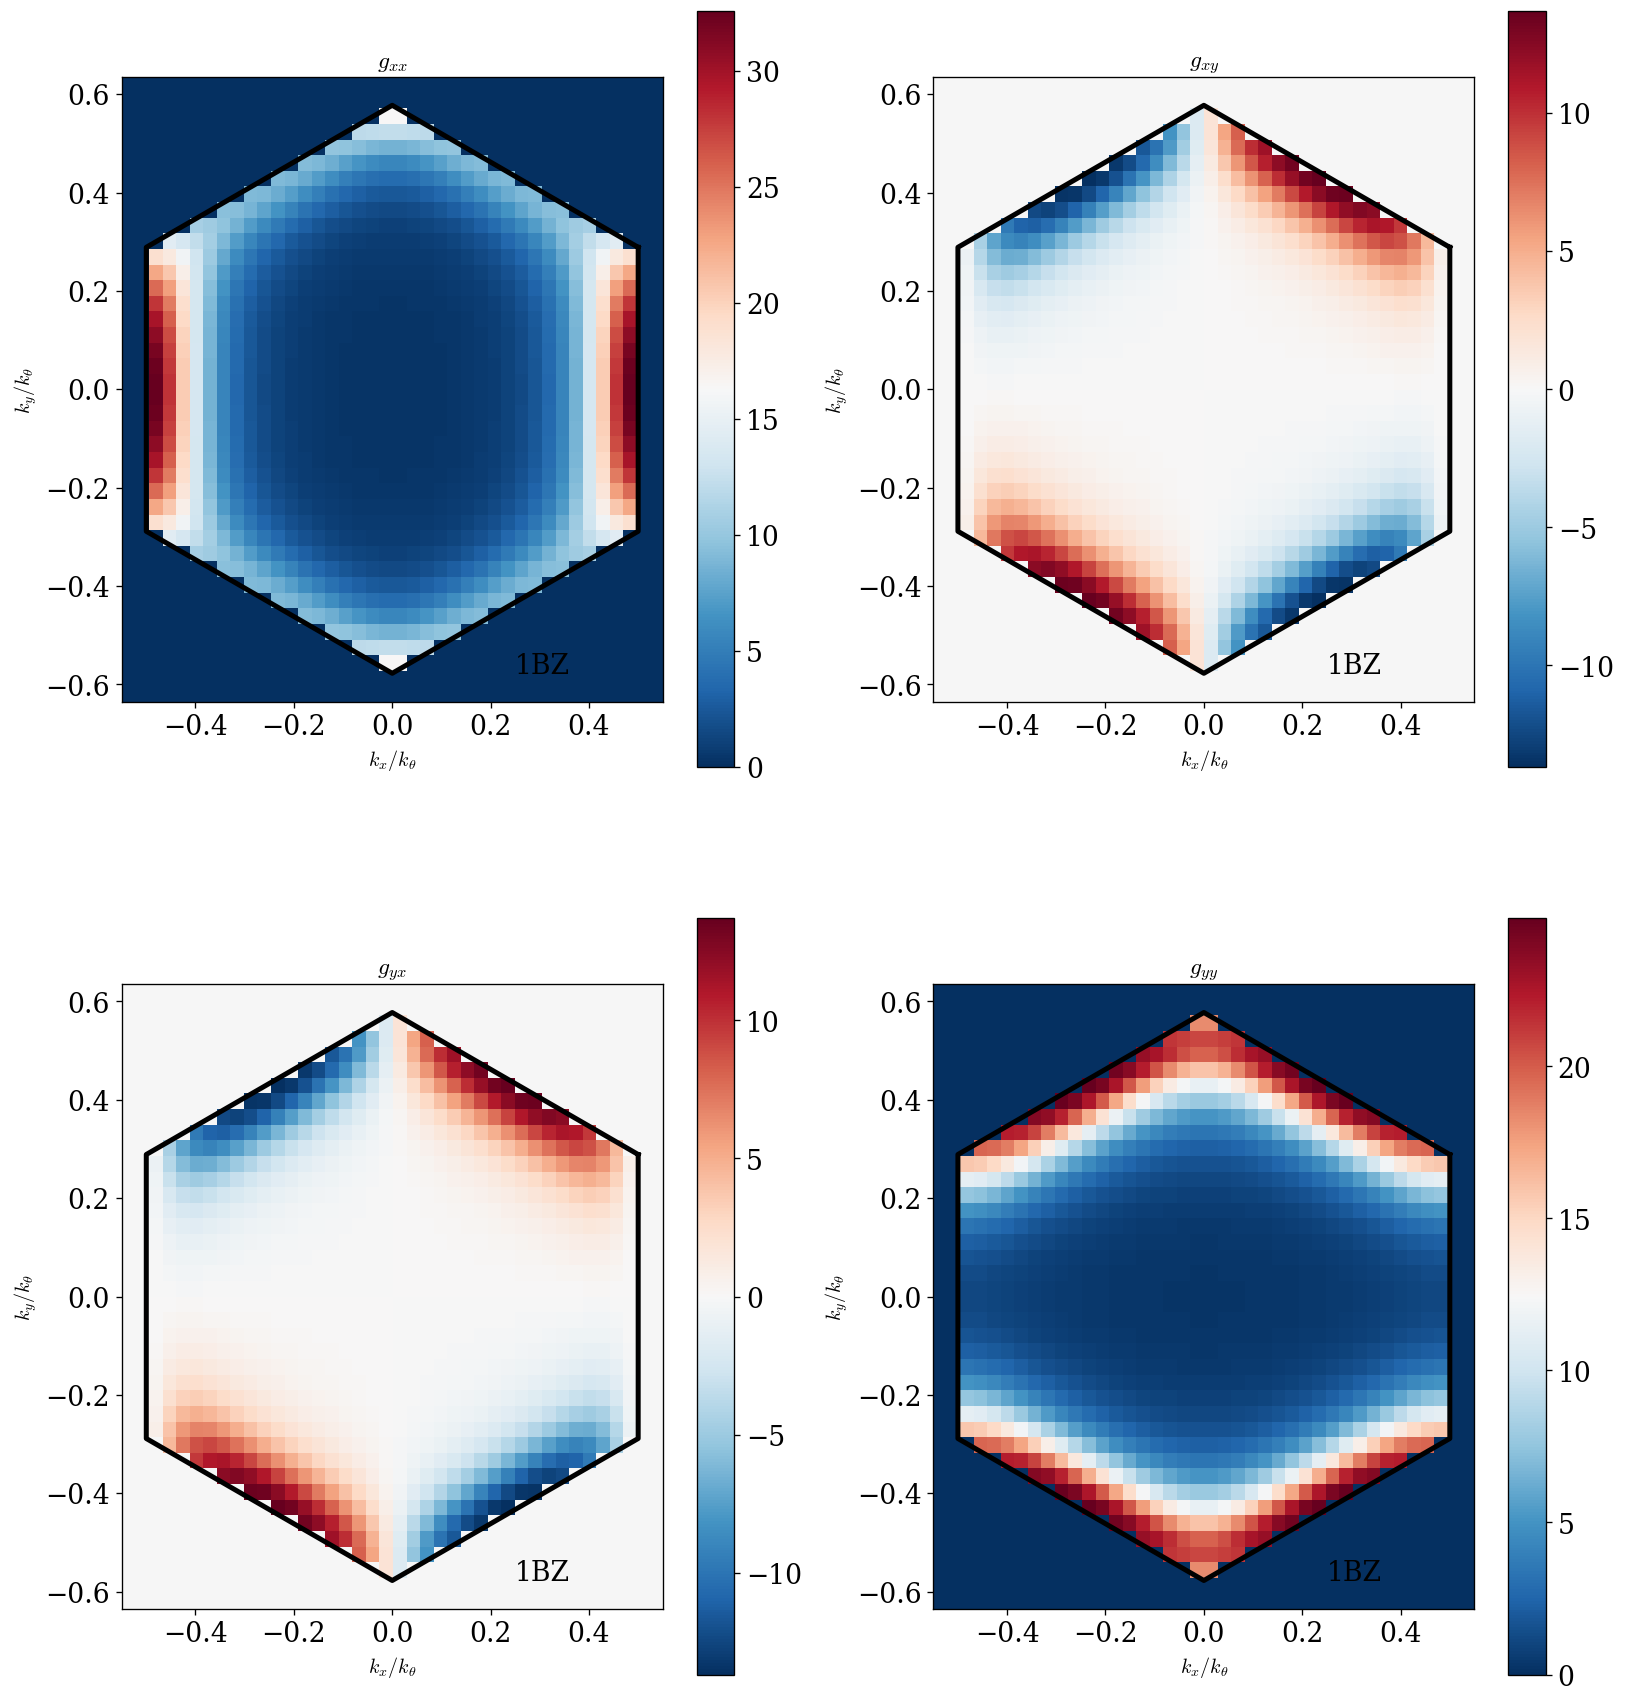

In [56]:
fig, ax = plt.subplots(2, 2, figsize=(16, 18))
scale = 1.1
kx = np.linspace(-scale * sys.kappa_pp[0], scale * sys.kappa_pp[0], 40)
ky = np.linspace(-scale * sys.kappa_p[1], scale * sys.kappa_p[1], 40)
KX, KY = np.meshgrid(kx, ky)
plot_metric(sys, ax, KX, KY, mask_bz=True)

# plt.xlabel(r'$k_x$')
# plt.ylabel(r'$k_y$')
plt.savefig("plots/quantum_metric.png")

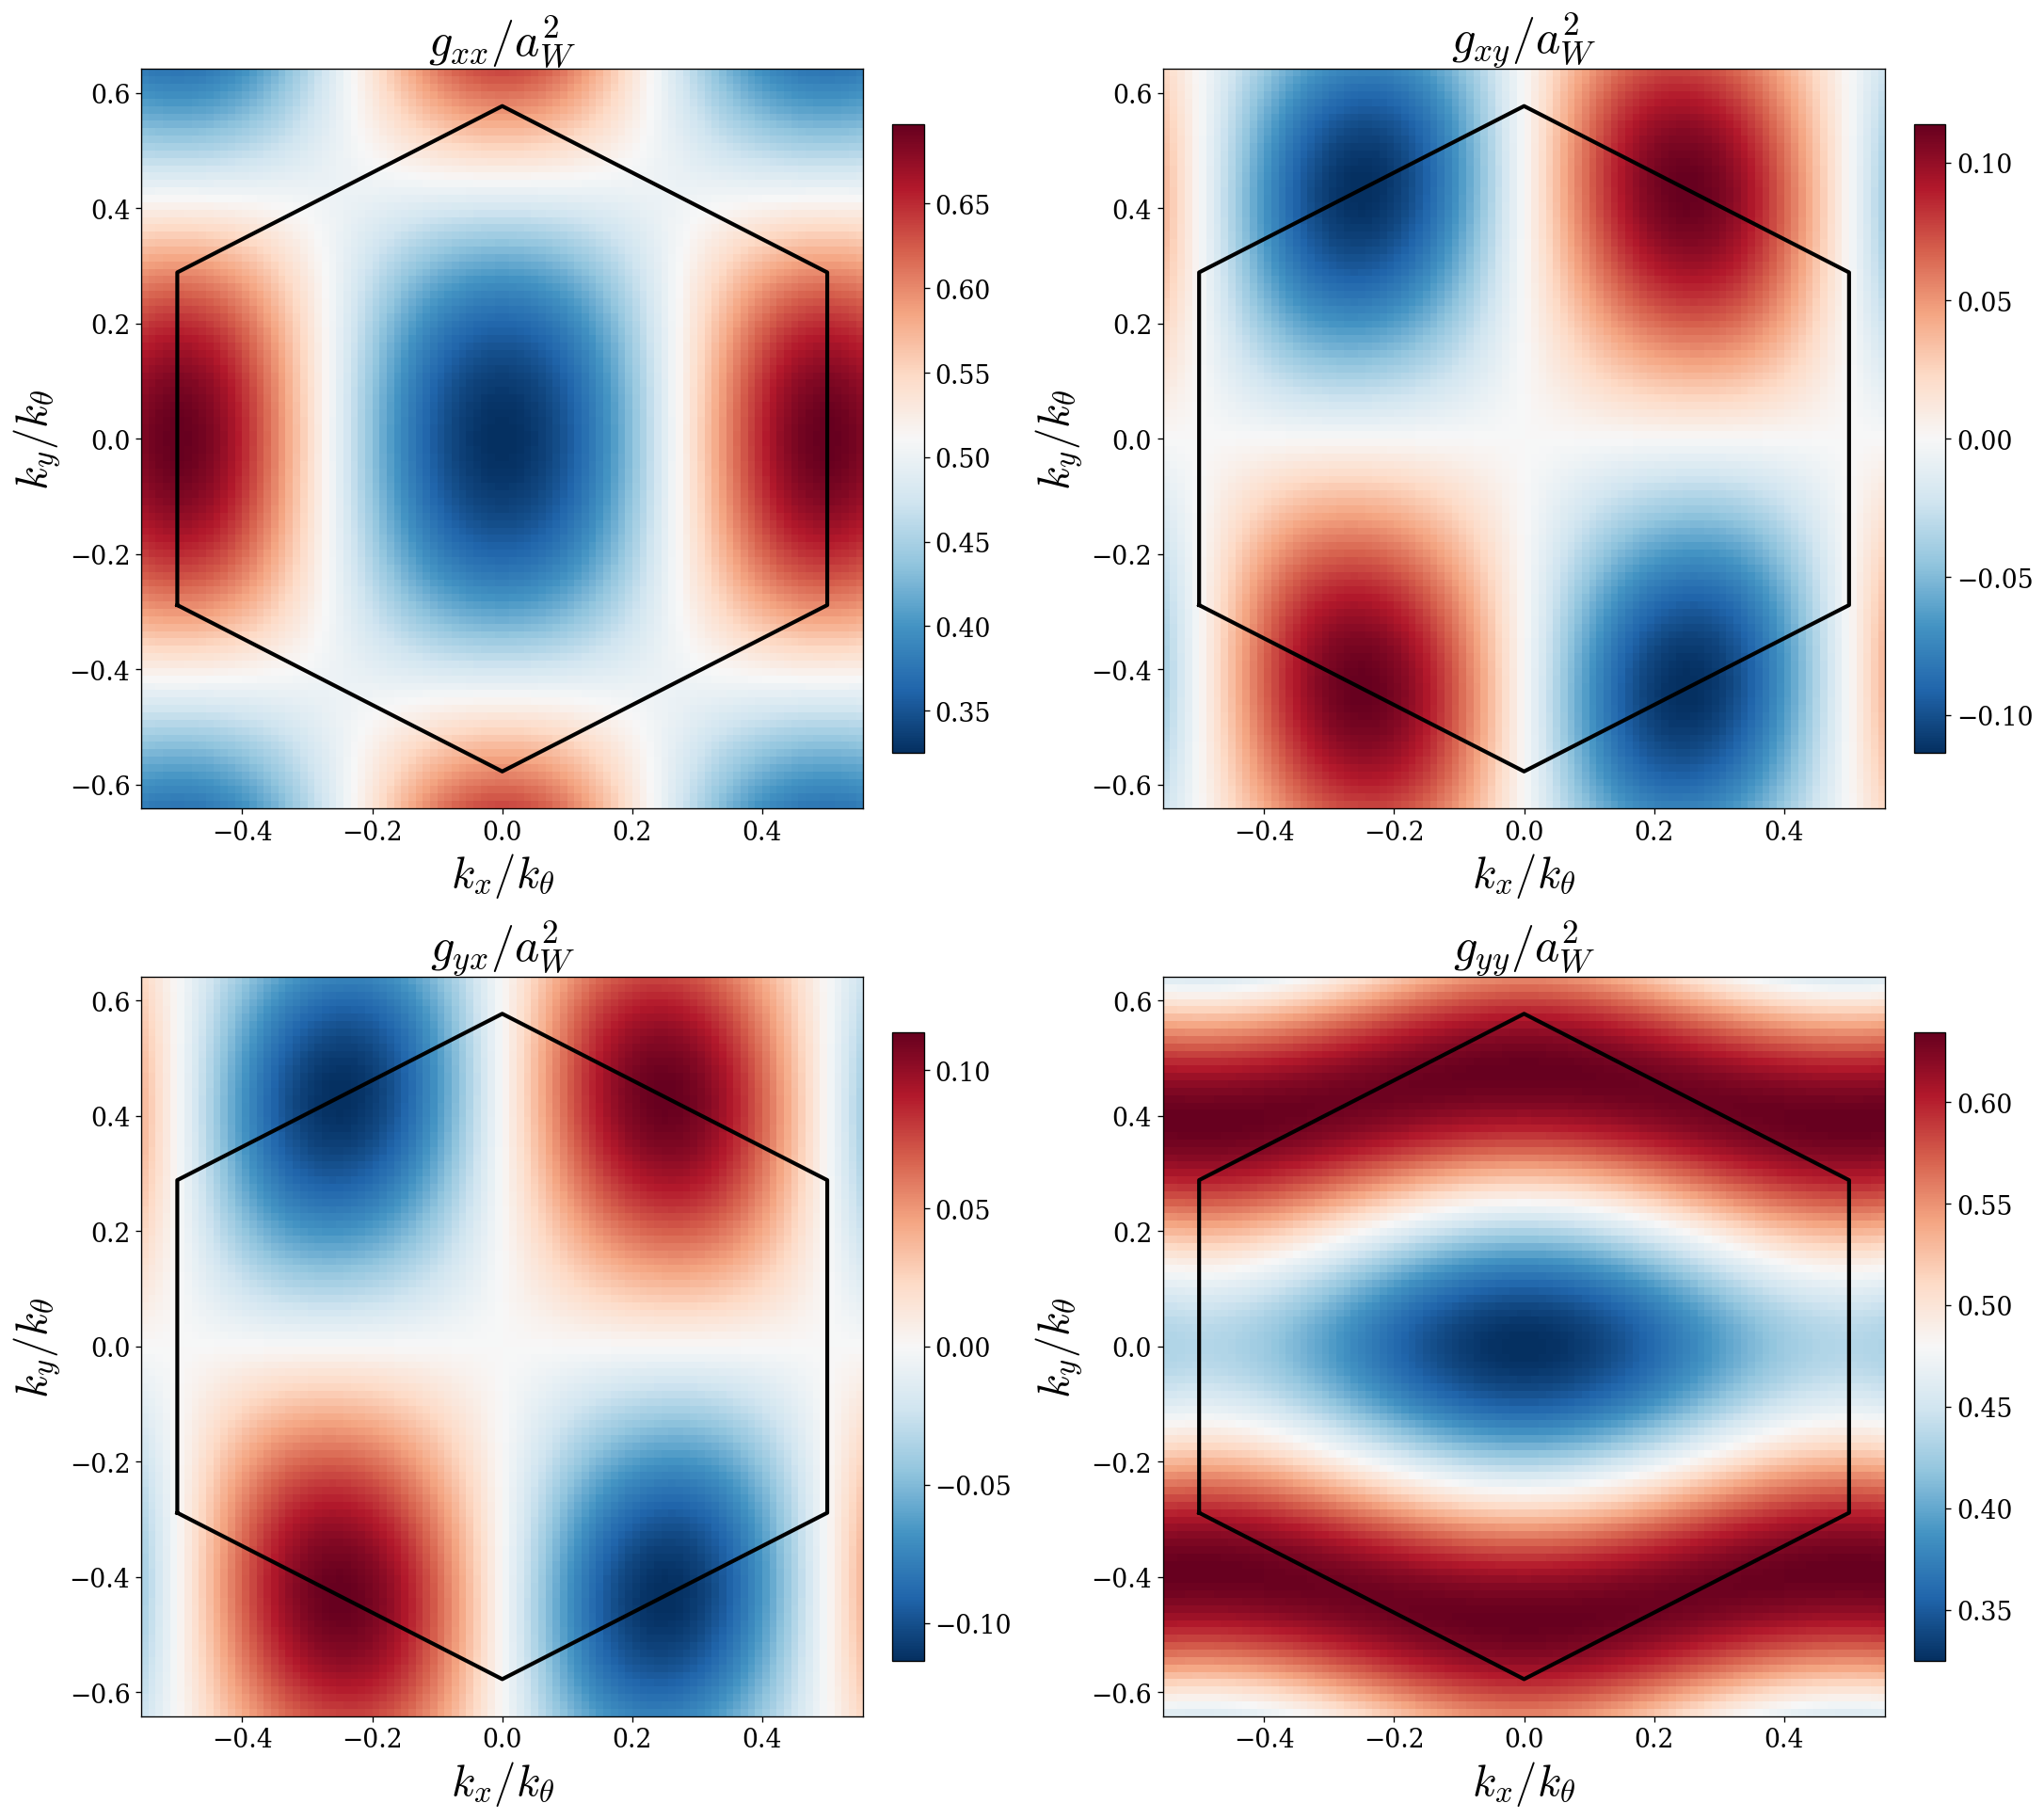

In [63]:
kx = scale * np.linspace(-sys.kappa_pp[0], sys.kappa_pp[0], 100)
ky = scale * np.linspace(-sys.kappa_p[1], sys.kappa_p[1], 100)
KX, KY = np.meshgrid(kx, ky)
analytic_metric.plot_metric_bz(KX / sys.aM, KY / sys.aM, 
                               sigma=utils.spread_harmonic_approx(sys.aM, sys.V, sys.psi_deg), 
                               aM=sys.aM, 
                               V=sys.V, 
                               psi=sys.psi_deg, normalize=True)
plt.savefig("plots/analytic_metric.pdf", dpi=300, bbox_inches='tight')

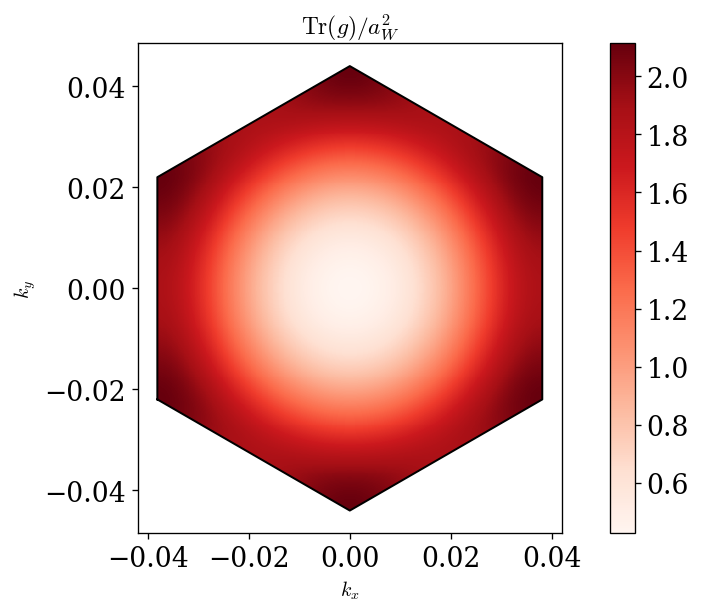

In [65]:
kx = np.linspace(-scale * sys.kappa_pp[0], scale * sys.kappa_pp[0], 500)
ky = np.linspace(-scale * sys.kappa_p[1], scale * sys.kappa_p[1], 500)
KX, KY = np.meshgrid(kx, ky)
analytic_metric.plot_trace_bz(KX / sys.aM, KY / sys.aM, 
                              sigma=utils.spread_perturbation(sys.aM, sys.V, sys.psi_deg), 
                              aM=sys.aM, 
                              V=sys.V, 
                              psi=sys.psi_deg)

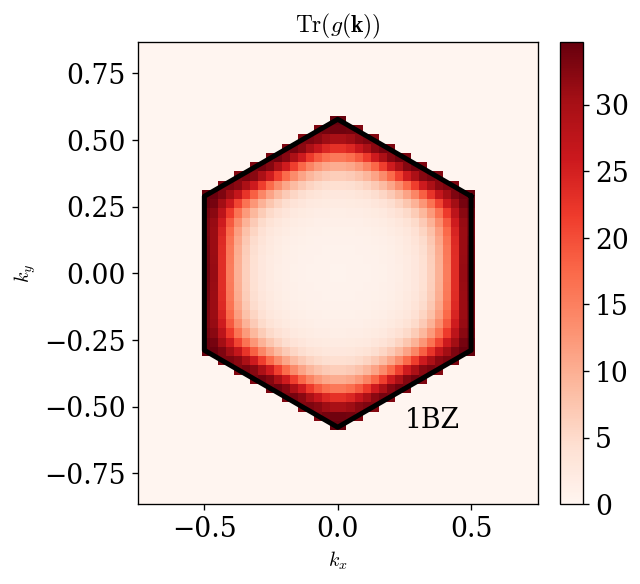

In [71]:
fig, ax = plt.subplots()
scale = 1.5
kx = np.linspace(-scale * sys.kappa_pp[0], scale * sys.kappa_pp[0], 50)
ky = np.linspace(-scale * sys.kappa_p[1], scale * sys.kappa_p[1], 50)
KX, KY = np.meshgrid(kx, ky)
plot_trace_metric(sys, ax, KX, KY)

Text(0, 0.5, '$k_y$')

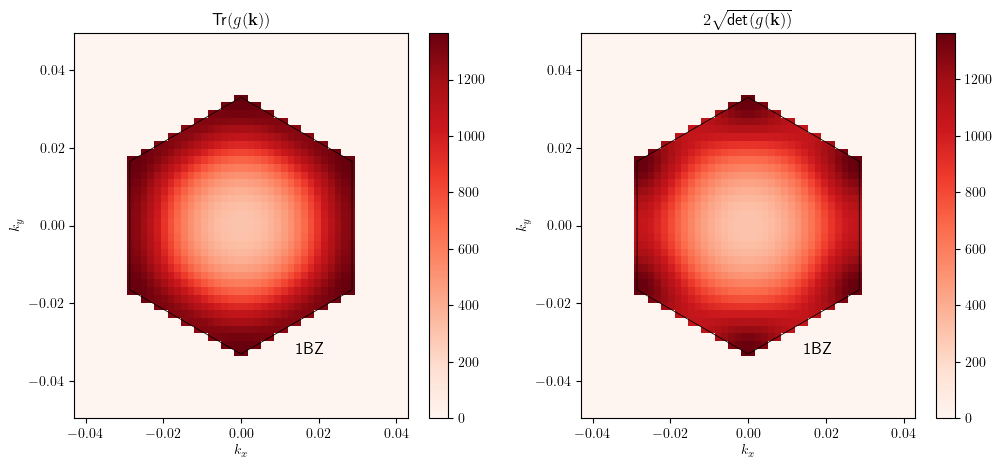

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(12, 5))
scale = 1.5
kx = np.linspace(-scale * sys.kappa_pp[0], scale * sys.kappa_pp[0], 50)
ky = np.linspace(-scale * sys.kappa_p[1], scale * sys.kappa_p[1], 50)
KX, KY = np.meshgrid(kx, ky)
sys.plot_trace_det_metric(ax, KX, KY)

plt.xlabel(r'$k_x$')
plt.ylabel(r'$k_y$')

Text(0, 0.5, '$k_y$')

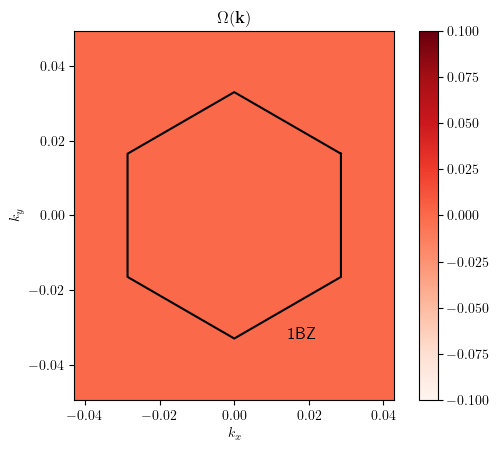

In [10]:
fig, ax = plt.subplots()
scale = 1.5
kx = np.linspace(-scale * sys.kappa_pp[0], scale * sys.kappa_pp[0], 50)
ky = np.linspace(-scale * sys.kappa_p[1], scale * sys.kappa_p[1], 50)
KX, KY = np.meshgrid(kx, ky)
sys.plot_berry_curvature(ax, KX, KY, abs_val=True)

plt.xlabel(r'$k_x$')
plt.ylabel(r'$k_y$')

Text(0, 0.5, '$k_y$')

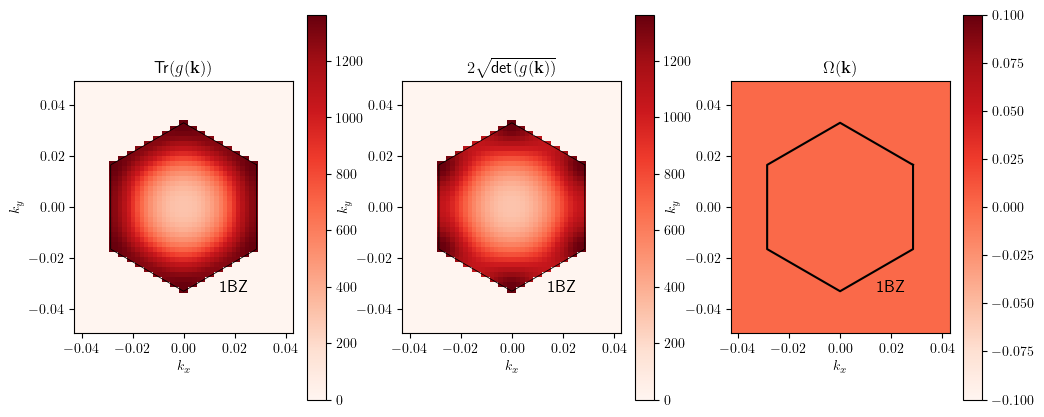

In [11]:
fig, ax = plt.subplots(1, 3, figsize=(12, 5))
scale = 1.5
kx = np.linspace(-scale * sys.kappa_pp[0], scale * sys.kappa_pp[0], 50)
ky = np.linspace(-scale * sys.kappa_p[1], scale * sys.kappa_p[1], 50)
KX, KY = np.meshgrid(kx, ky)
sys.plot_trace_metric(ax[0], KX, KY)
sys.plot_det_metric(ax[1], KX, KY)
sys.plot_berry_curvature(ax[2], KX, KY, abs_val=True)

plt.xlabel(r'$k_x$')
plt.ylabel(r'$k_y$')

## K-mesh

Text(0, 0.5, '$k_y$')

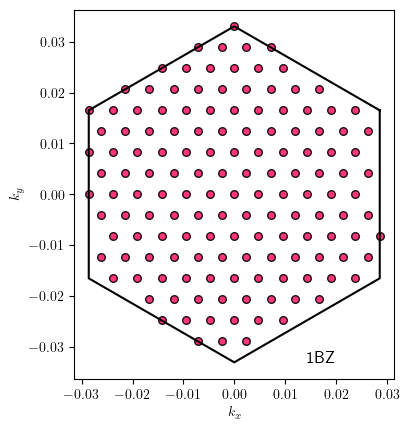

In [12]:
fig, ax = plt.subplots()
scale = 1.5
sys.plot_k_mesh(ax, Nx=12, Ny=12)

ax.set_aspect('equal')
plt.xlabel(r'$k_x$')
plt.ylabel(r'$k_y$')

## Extra

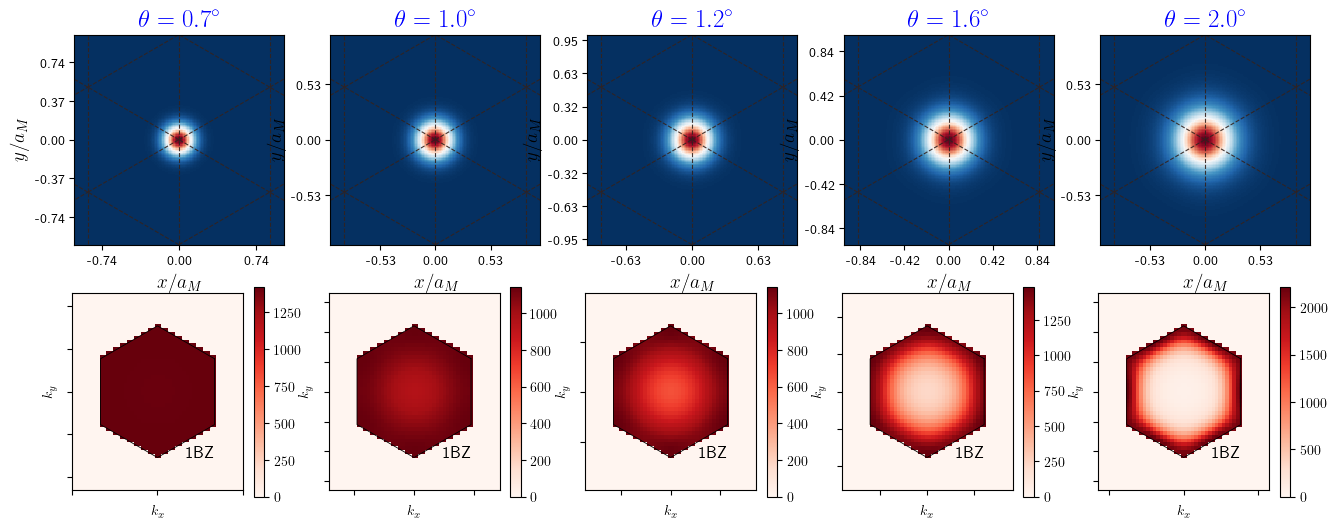

In [13]:
fig, ax = plt.subplots(2, 5, figsize=(16, 6))
scale = 1.0

thetas = [0.7, 1.0, 1.2, 1.6, 2.0]

for i, th in enumerate(thetas):
    sys.theta_deg = th
    aMi = sys.aM
    scale = 1.0

    extent = [-scale * sys.aM, scale * sys.aM, -scale * sys.aM, scale * sys.aM]
    k_points = sys.mesh_k_unit_cell()
    x = np.linspace(-2 * sys.aM, 2 * sys.aM, 300)
    y = np.linspace(-2 * sys.aM, 2 * sys.aM, 300)
    X, Y = np.meshgrid(x, y)
    im = sys.plot_wannier_function(ax[0,i], X, Y, k_points)#, cmap='coolwarm')
    sys.plot_triangular_lattice(ax[0,i], extent)

    ax[0,i].xaxis.set_major_formatter(FuncFormatter(lambda val, pos, L=aMi: f'{val/L:.2f}'))
    ax[0,i].yaxis.set_major_formatter(FuncFormatter(lambda val, pos, L=aMi: f'{val/L:.2f}'))
    ax[0,i].set_xlabel(r'$x/a_M$', fontsize=14)
    ax[0,i].set_ylabel(r'$y/a_M$', fontsize=14)
    ax[0,i].set_title(r'$\theta = {:.1f}^\circ$'.format(th), fontsize=18, color='blue')
    #ax[0,i].colorbar(im, ax=ax, label=r'$|\psi(\mathbf{r})|^2$', orientation='vertical');

    scale = 1.5
    kx = np.linspace(-scale * sys.kappa_pp[0], scale * sys.kappa_pp[0], 50)
    ky = np.linspace(-scale * sys.kappa_p[1], scale * sys.kappa_p[1], 50)
    KX, KY = np.meshgrid(kx, ky)
    sys.plot_trace_metric(ax[1,i], KX, KY)

    ax[1,i].set_xlabel(r'$k_x$')
    ax[1,i].set_ylabel(r'$k_y$')
    ax[1,i].set_xticklabels([])
    ax[1,i].set_yticklabels([])
    ax[1,i].set_title("")

In [14]:
thetas = np.linspace(0.5, 2.0, 20)
max_list = []
min_list = []

for i, th in enumerate(thetas):
    sys.theta_deg = th
    aMi = sys.aM
    scale = 1.0
    k_points = sys.mesh_k_unit_cell(Nx=21, Ny=21)
    k_points_bz = sys.map_to_first_BZ(k_points)
    g_xx, g_xy, g_yy = sys.quantum_metric(k_points=k_points_bz)
    tr = g_xx + g_yy

    max_list.append(np.max(tr))
    min_list.append(np.min(tr))

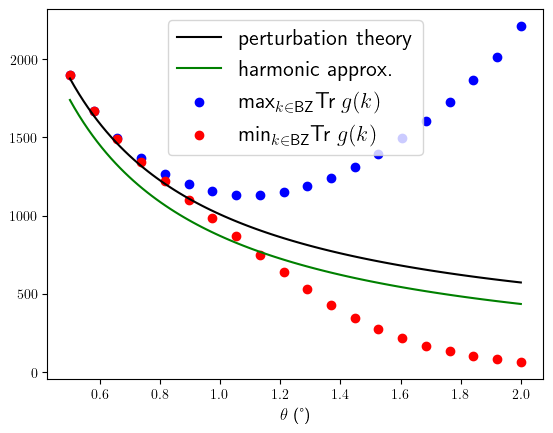

In [15]:
max_array = np.array(max_list)
min_array = np.array(min_list)

thetas2 = np.linspace(0.5, 2.0, 100)
aMs = sys.a0 / (2 * np.sin(np.radians(thetas2) / 2))

plt.plot(thetas2, utils.spread_perturbation(aMs, sys.V, sys.psi)**2, label=r'perturbation theory', color='k')
plt.plot(thetas2, utils.spread_harmonic_approx(aMs, sys.V, sys.psi)**2, label=r'harmonic approx.', color='g')
plt.scatter(thetas, max_array, label=r'$\text{max}_{k\in\text{BZ}} \text{Tr}\;g(k)$', color='blue')
plt.scatter(thetas, min_array, label=r'$\text{min}_{k\in\text{BZ}} \text{Tr}\;g(k)$', color='red')
plt.xlabel(r'$\theta$ (°)', fontsize=12)
plt.legend(fontsize=16)
plt.show()

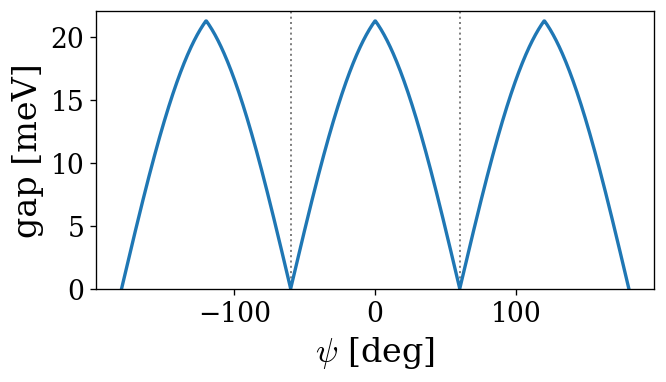

In [ ]:
fig, ax = plt.subplots(figsize=(6, 3))

psi_list = np.linspace(-180, 180, 1000)
gap_list = []

for p in psi_list:
    sys.psi_deg = p
    gap_list.append(-1 * sys.calculate_gap())

ax.vlines([-60, 60], ymin=0, ymax=25, color='gray', linewidth=1.2, linestyle=':', label=r'$\psi^* = \pm 60^\circ$')

ax.plot(psi_list, gap_list)
ax.set_xlabel(r'$\psi$ [deg]', fontsize=20)
ax.set_ylabel(r"gap [meV]", fontsize=20)  
ax.set_ylim([0, 22.0]) 
    
plt.savefig("plots/gap.pdf", dpi=300, bbox_inches='tight')